# Session 2 - What a flexible model cannot do

**AI in Quantitative Biology - practical 2 of 3 (90 min)**

In session 1 a two-parameter law described the metabolic rate of 422 mammals. Today we give the
same data to *machine-learning* models that assume nothing about the shape of the relation: nearest
neighbours, a random forest and a neural network.

**Suppose we train every model only on mammals lighter than 1 kg. Which one predicts the
elephant?** Write your guess down now.

| Part | Topic | Time |
|---|---|---|
| 1 | Four models, one curve | 20 min |
| 2 | Predict the big ones | 25 min |
| 3 | Species are not independent | 20 min |
| 4 | A law that breaks | 25 min |

✏️ marks exercises and ❓ questions to discuss with your neighbour: try them yourself first, the solution follows right after.

## Setup

Runs on a laptop CPU in about a minute. The data are in the `data/` folder of the course repository.
The cell below finds it in the folders above the notebook.

In [ ]:
# @title Setup: imports and data (run me)
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, GroupKFold, cross_val_score
from sklearn.metrics import r2_score

RNG = 0                                         # fixed seed: everyone gets the same numbers
pd.set_option("display.precision", 3)
warnings.filterwarnings("ignore", category=UserWarning)

import os
from pathlib import Path

def find_data_dir():
    "$QBIO_DATA if set, else the `data/` folder of the course repository (here or above)."
    if os.environ.get("QBIO_DATA"):
        return Path(os.environ["QBIO_DATA"])
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "anage.tsv").exists():
            return p / "data"
    raise FileNotFoundError("Cannot find data/: run the notebook inside the course repository, "
                            "or set QBIO_DATA to the path of its data/ folder")

DATA_DIR = find_data_dir()
print("data from", DATA_DIR)

anage = pd.read_csv(DATA_DIR / "anage.tsv", sep="\t")
mam = anage[anage["class"] == "Mammalia"].dropna(subset=["bmr_W", "bmr_mass_g"])
X = np.log10(mam[["bmr_mass_g"]].values)        # one feature: log10 body mass (g)
y = np.log10(mam["bmr_W"].values)               # target: log10 metabolic rate (W)
print(X.shape, y.shape)

data from /home/toni/Sync/teaching/c-courses/2026 AI QBio/classes/data
(422, 1) (422,)


## Part 1 - Four models, one curve

| model | how it predicts | parameters |
|---|---|---|
| **linear** | the straight line of session 1 (Kleiber's law) | 2 |
| **kNN** | average of the 10 species closest in mass | none: it keeps the data |
| **random forest** | average of 200 decision trees, each a staircase of "mass < threshold?" questions | thousands of thresholds |
| **neural network** (MLP) | two layers of 64 units, weights found by gradient descent | about 4 400 weights |

To compare them fairly we use **5-fold cross-validation**: split the species in 5 groups, train on
4, predict the 5th, rotate. Each species is predicted once by a model that never saw it.
`cross_val_score` does it for us and returns one R² per fold.

In [ ]:
def make_models(seed=RNG):
    return {
        "linear": LinearRegression(),
        "kNN": KNeighborsRegressor(n_neighbors=10),
        "random forest": RandomForestRegressor(n_estimators=200, random_state=seed),
        "neural network": make_pipeline(StandardScaler(), MLPRegressor(
            hidden_layer_sizes=(64, 64), max_iter=5000, random_state=seed)),
    }

cv = KFold(n_splits=5, shuffle=True, random_state=RNG)
for name, model in make_models().items():
    r2 = cross_val_score(model, X, y, cv=cv, scoring="r2")
    print(f"{name:15s} R2 = {r2.mean():.3f} +/- {r2.std():.3f}")

linear          R2 = 0.949 +/- 0.005
kNN             R2 = 0.947 +/- 0.007


random forest   R2 = 0.928 +/- 0.011


neural network  R2 = 0.953 +/- 0.003


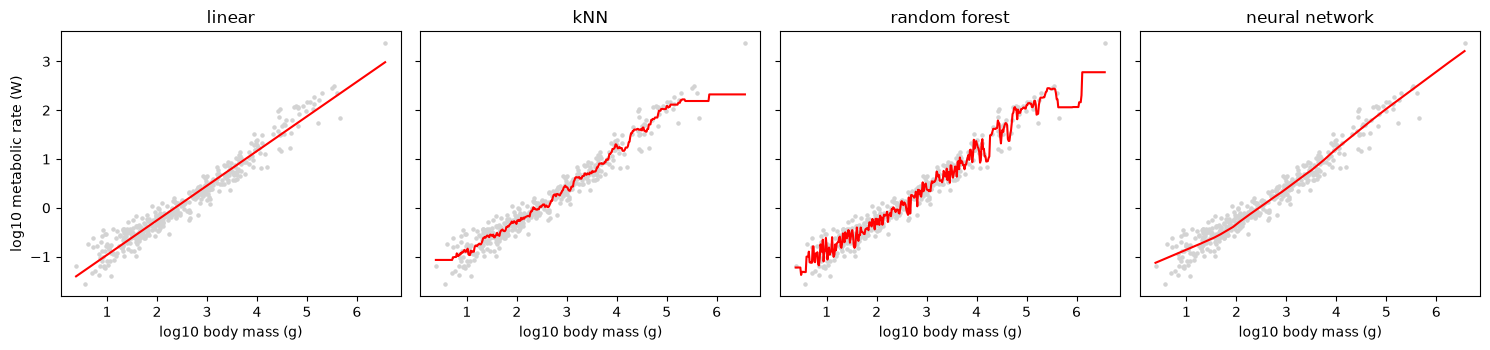

In [ ]:
grid = np.linspace(X.min(), X.max(), 400)[:, None]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
for ax, (name, model) in zip(axes, make_models().items()):
    ax.scatter(X, y, s=5, color="lightgrey")
    ax.plot(grid, model.fit(X, y).predict(grid), "r", lw=1.5)
    ax.set_title(name); ax.set_xlabel("log10 body mass (g)")
axes[0].set_ylabel("log10 metabolic rate (W)"); plt.tight_layout()

❓ Which model is best? Describe the four curves.

**Answer.** They cannot be told apart: all four reach R² ≈ 0.93 - 0.95, and the differences are
of the size of the fold-to-fold spread. The curves differ in character: a line, a wobbly average
(kNN), a staircase (forest), a smooth bent line (network). The flexible models wiggle around the
law without improving on it. Two parameters were enough, and several thousand did not hurt.

So far there is no reason to prefer the law, apart from taste.

## Part 2 - Predict the big ones

Now the experiment of the first page. Imagine that only small mammals had ever been measured:
we **train below 1 kg** and **test above 1 kg**.

train: 279 mammals below 1 kg,  test: 143 above


measured elephant: 2336 W


,R2 above 1 kg,elephant (W)
model,,
linear,0.787,415.472
kNN,-1.059,2.895
random forest,-1.041,2.930
neural network,0.830,401.556


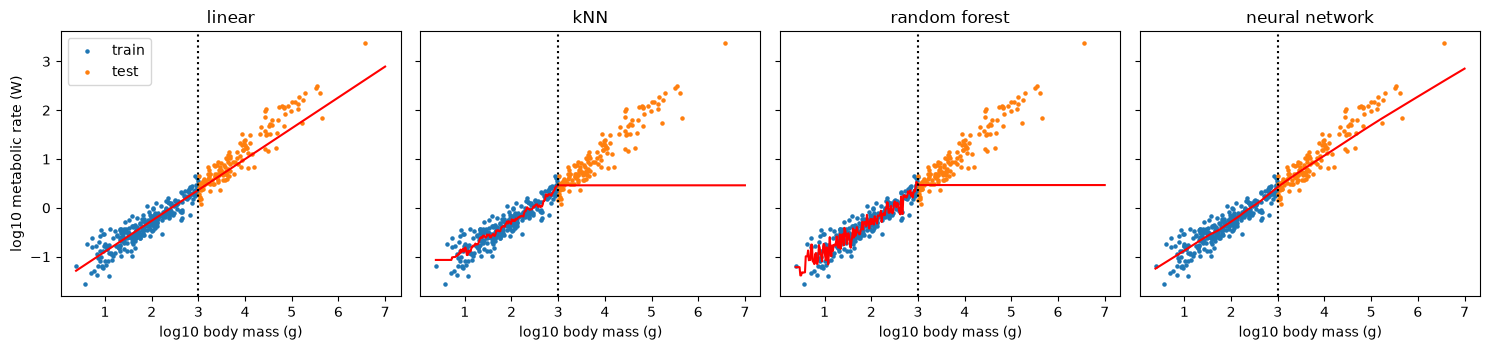

In [ ]:
small = X[:, 0] < 3                             # log10(1000 g) = 3
print(f"train: {small.sum()} mammals below 1 kg,  test: {(~small).sum()} above")

elephant = np.log10([[3_672_000]])
grid = np.linspace(X.min(), 7, 400)[:, None]

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6), sharey=True)
rows = []
for ax, (name, model) in zip(axes, make_models().items()):
    model.fit(X[small], y[small])
    rows.append({"model": name,
                 "R2 above 1 kg": r2_score(y[~small], model.predict(X[~small])),
                 "elephant (W)": 10 ** model.predict(elephant)[0]})
    ax.scatter(X[small], y[small], s=5, color="C0", label="train")
    ax.scatter(X[~small], y[~small], s=5, color="C1", label="test")
    ax.plot(grid, model.predict(grid), "r", lw=1.5)
    ax.axvline(3, color="k", ls=":")
    ax.set_title(name); ax.set_xlabel("log10 body mass (g)")
axes[0].set_ylabel("log10 metabolic rate (W)"); axes[0].legend(); plt.tight_layout()

print("measured elephant: 2336 W")
pd.DataFrame(rows).set_index("model")

❓ What does each model do to the right of the dotted line? Who predicts the elephant?

**Answer.**
* **kNN and the random forest go flat.** Both predict by averaging training animals, so they can
  never return a value larger than the ones they have seen. For them an elephant is a big rat,
  about 3 W. R² is negative: worse than predicting the mean of the test set.
* **The line keeps going** and predicts about 400 W. It is still 5 times too low, because the
  slope fitted on small mammals (0.63) is lower than the slope among large ones (remember the bend
  of session 1), but it is right within an order of magnitude, 3.5 orders of magnitude away from
  its training data.
* **The neural network** continues along a straight line too: outside its training range a
  network of this kind (ReLU units) is linear. Here it lands near the law. Is that reliable?

A neural network starts from random weights. Let us train it five times with different seeds.

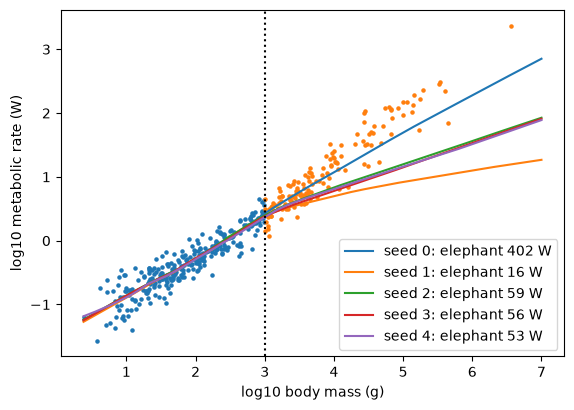

In [ ]:
plt.figure(figsize=(6.5, 4.5))
plt.scatter(X[small], y[small], s=5, color="C0")
plt.scatter(X[~small], y[~small], s=5, color="C1")
for seed in range(5):
    net = make_models(seed)["neural network"].fit(X[small], y[small])
    plt.plot(grid, net.predict(grid), lw=1.5, label=f"seed {seed}: elephant {10 ** net.predict(elephant)[0]:.0f} W")
plt.axvline(3, color="k", ls=":")
plt.xlabel("log10 body mass (g)"); plt.ylabel("log10 metabolic rate (W)"); plt.legend();

❓ Where do the five networks agree, and where not? What would you tell someone who used seed 0?

**Answer.** Below 1 kg the five curves coincide: the data pin them down. Above, each one leaves
in its own direction and the prediction for the elephant ranges from 16 W to 400 W. Nothing in
the training data tells the network which direction is right, so the choice is made by the random
initialisation. Seed 0 was luck.

This is the difference between **interpolation** and **extrapolation**. Inside the data, any
reasonable model works and the data decide. Outside, the answer comes from the *assumptions built
into the model*: "nothing new happens" for a forest, "continue straight in log-log space" for the
law. The law extrapolates because its assumption happens to be good physics, not because linear
regression is a better algorithm.

✏️ **Exercise 2.1.** Do the reverse: train on mammals **above** 1 kg and predict the small ones.
Compare the linear model, kNN and the random forest.

In [ ]:
for name, model in list(make_models().items())[:3]:
    model.fit(X[~small], y[~small])
    print(f"{name:15s} R2 below 1 kg = {r2_score(y[small], model.predict(X[small])):.2f}")

linear          R2 below 1 kg = 0.54
kNN             R2 below 1 kg = -2.71


random forest   R2 below 1 kg = -2.11


**Answer.** Same picture: kNN and the forest fail completely (R² about -2 to -3), the line still
explains about half of the variance (R² 0.54). It is less good than before because the slope of
large mammals (0.82) is too steep for small ones: the law is bent, and a straight line pays for
it when it has to travel far.

## Part 3 - Species are not independent

Extrapolation is not only about size. In session 1 the lifespan of mammals was poorly predicted
by mass alone (R² 0.50). Let us add three life-history traits and predict
**maximum longevity** from mass, age at maturity, gestation time and litter size.

In [ ]:
features = ["adult_mass_g", "female_maturity_days", "gestation_days", "litter_size"]
life = anage[anage["class"] == "Mammalia"].dropna(subset=features + ["longevity_yr"])
XL = np.log10(life[features].values)
yL = np.log10(life["longevity_yr"].values)
print(len(life), "mammals,", life["order"].nunique(), "orders,", life["family"].nunique(), "families")

models3 = {
    "linear": LinearRegression(),
    "kNN": make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
    "random forest": RandomForestRegressor(n_estimators=300, random_state=RNG),
}
random_cv = {name: cross_val_score(m, XL, yL, cv=cv, scoring="r2").mean() for name, m in models3.items()}
pd.Series(random_cv, name="R2, random 5-fold CV").to_frame()

765 mammals, 24 orders, 115 families


,"R2, random 5-fold CV"
linear,0.777
kNN,0.792
random forest,0.803


With four features, R² rises to about 0.8, and here the flexible models do slightly better than
the linear one.

But what does "a species the model never saw" mean? With a random split, when the model is
tested on the Norway rat it has trained on the black rat and on a hundred other rodents. Species
are related by evolution: close relatives have similar bodies *and* similar lifespans, for
reasons that our four features may not capture.

A harder and often more relevant question: **how well do we predict a kind of mammal that is
entirely new to the model?** `GroupKFold` keeps all species of the same **order** (rodents,
bats, primates, ...) together, either in training or in test.

In [ ]:
orders = life["order"].values
order_cv = {name: cross_val_score(m, XL, yL, cv=GroupKFold(n_splits=5), groups=orders, scoring="r2").mean()
            for name, m in models3.items()}
table = pd.DataFrame({"random CV": random_cv, "orders held out": order_cv})
table

,random CV,orders held out
linear,0.777,0.585
kNN,0.792,0.497
random forest,0.803,0.479


❓ What happened? Which model loses most? Which number is "the" accuracy of the model?

**Answer.** All models lose, and the flexible ones lose most: the random forest falls from 0.80
to about 0.48, below the linear model (0.59). With random splits a flexible model can look up
the close relatives of each test species; that is useful if your next species is another rodent,
and useless if it is the first bat.

Neither number is wrong. They answer different questions: "another species from the groups I
know" and "a species from a group I have never seen". A published accuracy always describes
some population; ask which one. We will meet the same problem in session 3 with proteins, where
relatives are called *homologues*.

✏️ **Exercise 3.1.** Train the random forest on all mammals **except bats** (`Chiroptera`) and
predict the bats. On average, are the predicted lifespans too long or too short, and by what
factor? Connect this with Part 5 of session 1.

In [ ]:
bats = orders == "Chiroptera"
rf = RandomForestRegressor(n_estimators=300, random_state=RNG).fit(XL[~bats], yL[~bats])
pred = rf.predict(XL[bats])
print(f"{bats.sum()} bats: predicted / true lifespan, geometric mean = {10 ** np.mean(pred - yL[bats]):.2f}")

48 bats: predicted / true lifespan, geometric mean = 0.80


**Answer.** The predictions are too short, by about 20% on average (ratio 0.80). Bats live longer
than other mammals with the same size and reproduction, and a model that has never seen a bat
cannot know. In session 1 this was a residual; here it is an error on new data. It is the same
fact seen from two sides.

## Part 4 - A law that breaks

A different kind of scaling: **how many genes fit in a genome?** The table lists the genome size
(in megabases, Mb) and the number of annotated genes for about 13 800 prokaryotes (bacteria and
archaea, complete genomes) and 4 700 eukaryotes (animals, plants, fungi, protists), from the NCBI
genome reports.

In [ ]:
genomes = pd.read_csv(DATA_DIR / "genomes.tsv", sep="\t")
print(genomes.groupby("domain").size())
genomes.sample(5, random_state=RNG)

domain
eukaryote      4685
prokaryote    13751
dtype: int64


,domain,group,subgroup,organism,size_mb,genes
2887,eukaryote,Fungi,Ascomycetes,Lasiosphaeria ovina,51.771,15256
15374,prokaryote,Terrabacteria group,Bacillota,NaN,1.609,1688
10432,prokaryote,Pseudomonadota,Gammaproteobacteria,NaN,4.530,4278
8326,prokaryote,Pseudomonadota,Alphaproteobacteria,NaN,8.416,7867
17893,prokaryote,Terrabacteria group,Cyanobacteriota/Melainabacteria group,NaN,7.408,6753


✏️ **Exercise 4.1.** Always look at the data first. Which eukaryotes have the most genes
according to this table? Do you believe it?

In [ ]:
genomes.sort_values("genes", ascending=False).head(10)[["group", "organism", "size_mb", "genes"]]

,group,organism,size_mb,genes
1014,Animals,Lynx pardinus,2413.210,4736081
4308,Plants,Olea europaea subsp. europaea,1316.680,2120687
1274,Animals,Mytilus galloprovincialis,1391.180,1200010
1314,Animals,Podarcis lilfordi,1460.100,991322
408,Animals,Solea senegalensis,608.698,667029
1309,Animals,Trichonephila clavipes,2874.350,528905
6,Animals,Pelobates cultripes,3094.940,231786
1284,Animals,Dreissena polymorpha,1797.940,194995
827,Animals,Cinara cedri,396.043,139239
4343,Plants,Lolium multiflorum,2462.090,138727


**Answer.** The Iberian lynx with 4.7 million genes, an olive tree with 2 million: these are
errors in the submitted annotations (probably features miscounted as genes), not biology. For
comparison, bread wheat, a famously gene-rich genome, has about 110 000. Public databases
contain such records, and no model will warn you. We drop the 8 entries above 150 000 genes.

In [ ]:
genomes = genomes[genomes["genes"] < 150_000]
pro = genomes[genomes["domain"] == "prokaryote"]
euk = genomes[genomes["domain"] == "eukaryote"]

Xp, yp = np.log10(pro[["size_mb"]].values), np.log10(pro["genes"].values)
Xe, ye = np.log10(euk[["size_mb"]].values), np.log10(euk["genes"].values)

law = LinearRegression().fit(Xp, yp)
print(f"prokaryotes: genes = {10 ** law.intercept_:.0f} * size^{law.coef_[0]:.3f}     R2 = {law.score(Xp, yp):.3f}")
print(f"median gene density: {(pro['genes'] / pro['size_mb']).median():.0f} genes per Mb")

prokaryotes: genes = 985 * size^0.964     R2 = 0.980
median gene density: 942 genes per Mb


For prokaryotes the law is almost exact: the exponent is close to 1, so gene number is
**proportional** to genome size, about one gene per 1 000 bases. A prokaryotic genome is genes
packed side by side.

The human genome has about 3 100 Mb. What does this law predict for us? We also ask a random
forest trained on the same prokaryotes.

human, annotated          :     57,816 genes
prokaryote law predicts   :  2,309,502
prokaryote forest predicts:     11,239

R2 on eukaryotes: law -11.9, forest -0.04


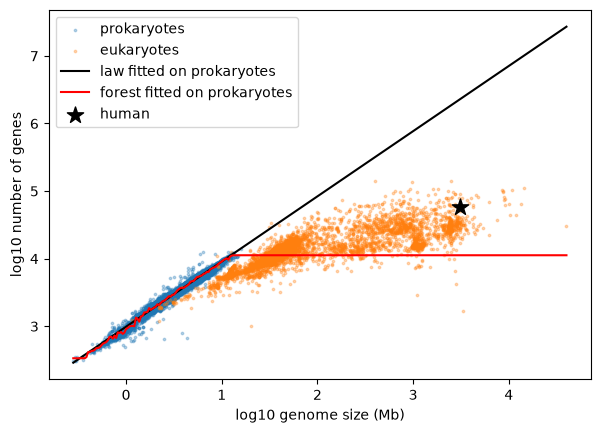

In [ ]:
forest = RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=RNG).fit(Xp, yp)

human = euk[euk["organism"] == "Homo sapiens"].iloc[0]
xh = np.log10([[human["size_mb"]]])
print(f"human, annotated          : {human['genes']:>10,.0f} genes")
print(f"prokaryote law predicts   : {10 ** law.predict(xh)[0]:>10,.0f}")
print(f"prokaryote forest predicts: {10 ** forest.predict(xh)[0]:>10,.0f}")

grid = np.linspace(Xp.min(), Xe.max(), 300)[:, None]
plt.figure(figsize=(7, 4.8))
plt.scatter(Xp, yp, s=3, alpha=0.3, label="prokaryotes")
plt.scatter(Xe, ye, s=3, alpha=0.3, label="eukaryotes")
plt.plot(grid, law.predict(grid), "k", lw=1.5, label="law fitted on prokaryotes")
plt.plot(grid, forest.predict(grid), "r", lw=1.5, label="forest fitted on prokaryotes")
plt.scatter(xh, np.log10(human["genes"]), color="k", marker="*", s=150, zorder=5, label="human")
plt.xlabel("log10 genome size (Mb)"); plt.ylabel("log10 number of genes"); plt.legend();

print(f"\nR2 on eukaryotes: law {r2_score(ye, law.predict(Xe)):.1f}, forest {r2_score(ye, forest.predict(Xe)):.2f}")

❓ The law that extrapolated so well in Part 2 now predicts 2.3 million human genes. The forest,
which failed in Part 2, says 11 000, much closer to the truth (about 58 000 annotated genes, of
which 20 000 code for proteins). Did the forest understand eukaryotes?

**Answer.** No. The forest does here exactly what it did with the elephant: it repeats the
largest value it has seen. This time "nothing new happens" is by chance closer to reality than
"continue straight", because gene number nearly stops growing. Neither model had any
information about eukaryotes, and neither gave any sign of being outside its domain. Extrapolation
succeeds when the assumption of the model matches the world, and you cannot check that from
inside the training data.

What changed is the biology. Eukaryotic genomes are mostly *not* genes: introns, repeats and
other non-coding DNA. The record holder in the table, a lungfish, has a genome of 40 000 Mb,
13 times ours, with about 30 000 genes. Genome size tells little about gene number or about
the complexity of the organism (the *C-value paradox*).

✏️ **Exercise 4.2.** Fit the exponent for eukaryotes as a whole, then separately for each `group`.
Which group is closest to the prokaryotic behaviour, which is furthest?

In [ ]:
print(f"all eukaryotes: exponent {np.polyfit(Xe[:, 0], ye, 1)[0]:.2f}, R2 = {np.corrcoef(Xe[:, 0], ye)[0, 1] ** 2:.2f}\n")
rows = []
for group, d in euk.groupby("group"):
    xg, yg = np.log10(d["size_mb"]), np.log10(d["genes"])
    rows.append({"group": group, "n": len(d), "median size (Mb)": d["size_mb"].median(),
                 "exponent": np.polyfit(xg, yg, 1)[0], "R2": np.corrcoef(xg, yg)[0, 1] ** 2})
pd.DataFrame(rows).set_index("group")

all eukaryotes: exponent 0.28, R2 = 0.60



,n,median size (Mb),exponent,R2
group,,,,
Animals,1414,1028.910,0.209,0.232
Fungi,2531,35.445,0.576,0.747
Other,23,62.108,0.520,0.506
Plants,406,528.340,0.344,0.499
Protists,303,34.194,0.569,0.638


**Answer.** For eukaryotes as a whole the exponent is 0.28 with R² 0.60: a genome 10 times larger
has only about twice the genes. Fungi and protists, with small compact genomes, keep an exponent
near 0.6 and a fairly tight relation. In animals the exponent is 0.2 and R² only 0.2: genome size
says almost nothing about gene number. The proportionality law holds where genomes are compact
and fades as non-coding DNA takes over.

## Summary

* **Inside the data, models agree.** A line, kNN, a random forest and a neural network all reach
  R² ≈ 0.95 on metabolic rate. Cross-validation cannot separate them.
* **Outside the data, assumptions decide.** Averaging models go flat, neural networks leave in a
  direction set by their random seed, a law continues its trend. The law was right for the
  elephant and wrong for the human genome.
* **"Unseen" has degrees.** A random split tests on close relatives of the training species;
  holding out whole orders cuts the R² of the random forest from 0.80 to 0.48.
* **No score computed on your data tells you where the model stops being valid.** That
  takes knowledge of the system, or new data from outside.

In session 3 we turn to protein sequences, where no two-parameter law exists and a neural network
earns its place. The same questions come with us: what is the simple baseline, and what does
"unseen" mean?

## References and data sources

**Data**

* `anage.tsv`: AnAge, the animal ageing and longevity database of the Human Ageing Genomic Resources (build 15; Tacutu et al. 2018), https://genomics.senescence.info/species/
* `genomes.tsv`: NCBI genome reports for prokaryotes and eukaryotes (Sayers et al. 2022), https://ftp.ncbi.nlm.nih.gov/genomes/GENOME_REPORTS/, downloaded 2026-11-11 and reduced to one row per species by `data_prep/make_scaling_datasets.py`.

**Further reading**

* Felsenstein J (1985). Phylogenies and the comparative method. *Am Nat* 125:1–15. [doi:10.1086/284325](https://doi.org/10.1086/284325) — why related species are not independent data points (Part 3)
* Kapoor S, Narayanan A (2023). Leakage and the reproducibility crisis in machine-learning-based science. *Patterns* 4:100804. [doi:10.1016/j.patter.2023.100804](https://doi.org/10.1016/j.patter.2023.100804) — a taxonomy of data leakage
* West GB, Brown JH, Enquist BJ (1997). A general model for the origin of allometric scaling laws in biology. *Science* 276:122–126. [doi:10.1126/science.276.5309.122](https://doi.org/10.1126/science.276.5309.122) — the scaling-law model
* Kleiber M (1932). Body size and metabolism. *Hilgardia* 6:315–353. [doi:10.3733/hilg.v06n11p315](https://doi.org/10.3733/hilg.v06n11p315)